# Bike-sharing demand: exploratory analysis

Hourly rentals of Capital Bikeshare (Washington D.C.), 2011-2012, with weather and calendar information. The goal of this notebook is to understand the **structure of demand** (seasonality, trend, weather sensitivity, anomalies) and turn it into modelling decisions for a day-ahead forecaster.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from bikeforecast.data import load_hourly

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110
df = load_hourly()
print(f'{len(df):,} hours from {df.index.min():%Y-%m-%d} to {df.index.max():%Y-%m-%d}')
df.head()

17,544 hours from 2011-01-01 to 2012-12-31


,cnt,casual,registered,temp_c,feels_like_c,humidity,windspeed_kmh,weather,holiday,workingday,is_filled
timestamp,,,,,,,,,,,
2011-01-01 00:00:00,16,3,13,9.84,14.395,81.0,0.0,1,0,0,0
2011-01-01 01:00:00,40,8,32,9.02,13.635,80.0,0.0,1,0,0,0
2011-01-01 02:00:00,32,5,27,9.02,13.635,80.0,0.0,1,0,0,0
2011-01-01 03:00:00,13,3,10,9.84,14.395,75.0,0.0,1,0,0,0
2011-01-01 04:00:00,1,0,1,9.84,14.395,75.0,0.0,1,0,0,0


## 1. Gaps in the raw data

In [2]:
filled = df[df['is_filled'] == 1]
print(f'{len(filled)} hours were missing from the raw file')
print('Missing hours by hour of day:')
print(filled.index.hour.value_counts().sort_index().to_dict())
filled.groupby(filled.index.date).size().sort_values(ascending=False).head(6)

165 hours were missing from the raw file
Missing hours by hour of day:
{0: 5, 1: 7, 2: 16, 3: 34, 4: 34, 5: 14, 6: 6, 7: 4, 8: 4, 9: 4, 10: 4, 11: 4, 12: 3, 13: 2, 14: 2, 15: 2, 16: 1, 17: 1, 18: 3, 19: 3, 20: 3, 21: 3, 22: 3, 23: 3}


2012-10-29    23
2011-01-27    16
2012-10-30    13
2011-01-18    12
2011-01-26     8
2011-08-28     7
dtype: int64

Most missing hours are between midnight and 6 am: hours with no rentals that were simply not written to the file (the smallest recorded count is 1). The big blocks are real shutdowns: **Hurricane Sandy** (29-30 Oct 2012), **Hurricane Irene** (27-28 Aug 2011) and winter storms in January 2011. Filling them with 0 is the truthful value; they are flagged in `is_filled`.

## 2. Trend and yearly seasonality

timestamp
2011    1243103
2012    2049576 
Growth 2011 -> 2012: 65%


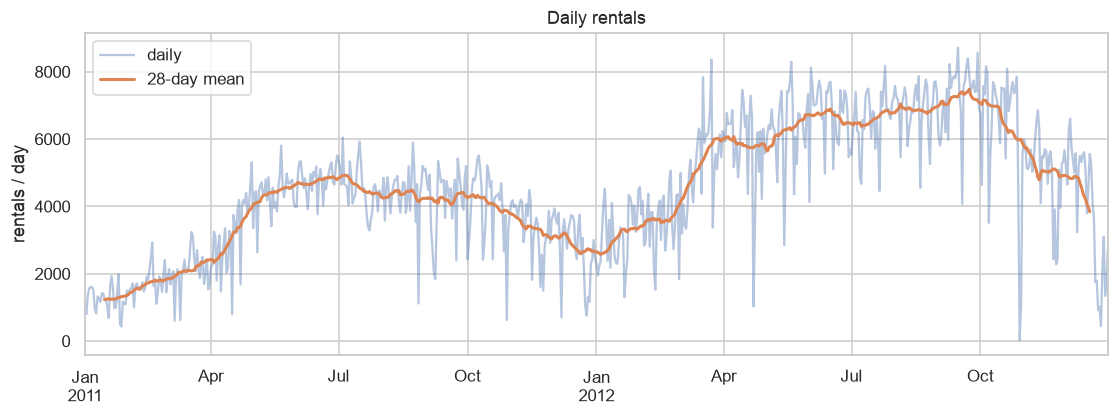

In [3]:
daily = df['cnt'].resample('D').sum()
yearly = daily.groupby(daily.index.year).sum()
print(yearly.to_string(), f'\nGrowth 2011 -> 2012: {yearly.iloc[1] / yearly.iloc[0] - 1:.0%}')
ax = daily.plot(figsize=(12, 3.8), alpha=0.4, label='daily')
daily.rolling(28, center=True).mean().plot(ax=ax, lw=2, label='28-day mean')
ax.set(title='Daily rentals', ylabel='rentals / day', xlabel='')
ax.legend();

Demand grew **65%** in a year on top of a strong summer/winter cycle. A model that predicts absolute counts from features like `month` will under-forecast the second year: tree models in particular cannot extrapolate beyond the target values they have seen. This motivates predicting demand **relative to its recent level**.

## 3. Daily and weekly seasonality

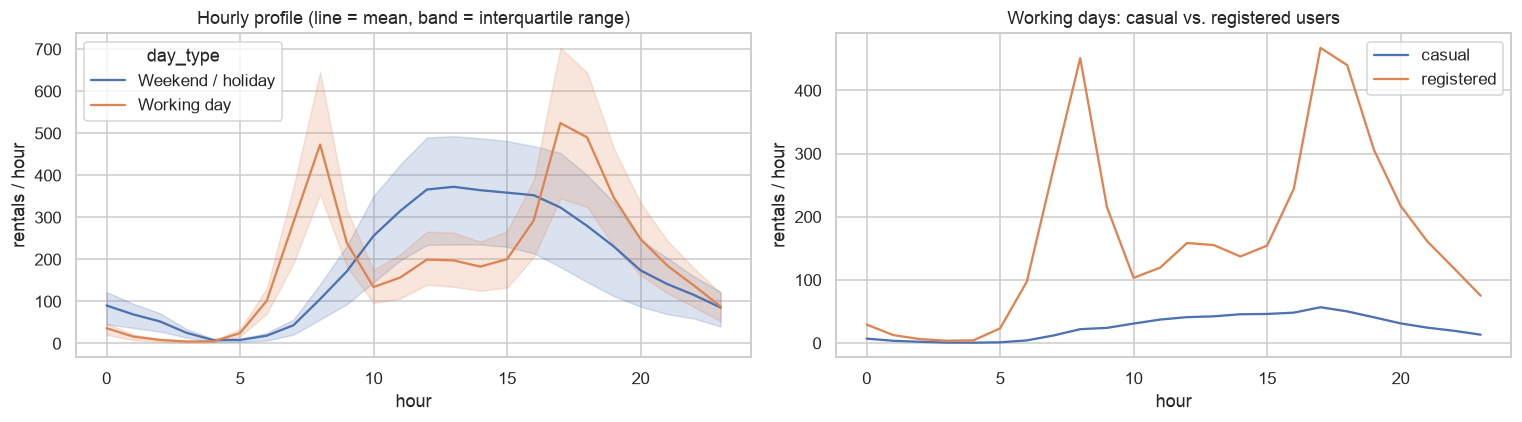

In [4]:
profile = df.assign(hour=df.index.hour,
                    day_type=np.where(df['workingday'] == 1, 'Working day', 'Weekend / holiday'))
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.lineplot(data=profile, x='hour', y='cnt', hue='day_type', errorbar=('pi', 50), ax=axes[0])
axes[0].set(title='Hourly profile (line = mean, band = interquartile range)', ylabel='rentals / hour')
users = profile.groupby(['day_type', 'hour'])[['casual', 'registered']].mean()
users.loc['Working day'].plot(ax=axes[1], title='Working days: casual vs. registered users')
axes[1].set(ylabel='rentals / hour')
fig.tight_layout()

Two completely different regimes:

* **Working days**: commuting peaks at 8 am and 5-6 pm, driven by registered (subscribed) users.
* **Weekends and holidays**: a single broad afternoon hump driven by leisure trips.

The forecaster therefore needs the interaction *hour × working day*; the Ridge model gets it as an explicit one-hot feature, LightGBM learns it from `hour` and `workingday`.

## 4. Autocorrelation

24     0.819
48     0.685
168    0.871
336    0.867
dtype: float64

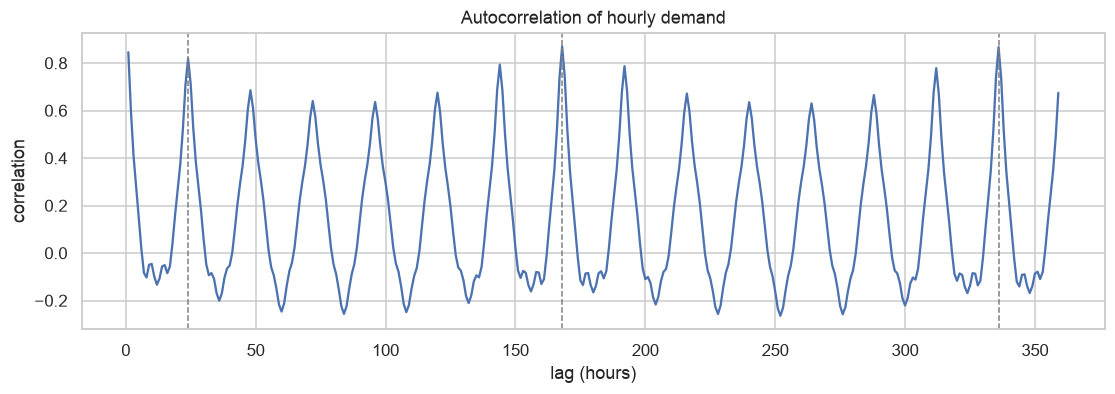

In [5]:
lags = range(1, 24 * 15)
acf = pd.Series([df['cnt'].autocorr(l) for l in lags], index=lags)
ax = acf.plot(figsize=(12, 3.5), title='Autocorrelation of hourly demand')
for lag in (24, 168, 336):
    ax.axvline(lag, color='grey', ls='--', lw=1)
ax.set(xlabel='lag (hours)', ylabel='correlation')
acf.loc[[24, 48, 168, 336]].round(3)

Peaks at **24 h** and **168 h** (one week). Since forecasts are made a day ahead, lags shorter than 24 h are not available; lags of 24, 48, 168 and 336 hours and a *same-hour-over-the-last-7-days* average are the demand features. The weekly lag is more informative than the daily one because it compares like with like (Monday with Monday), which is why the *same hour last week* naive forecast is the baseline to beat.

## 5. Weather

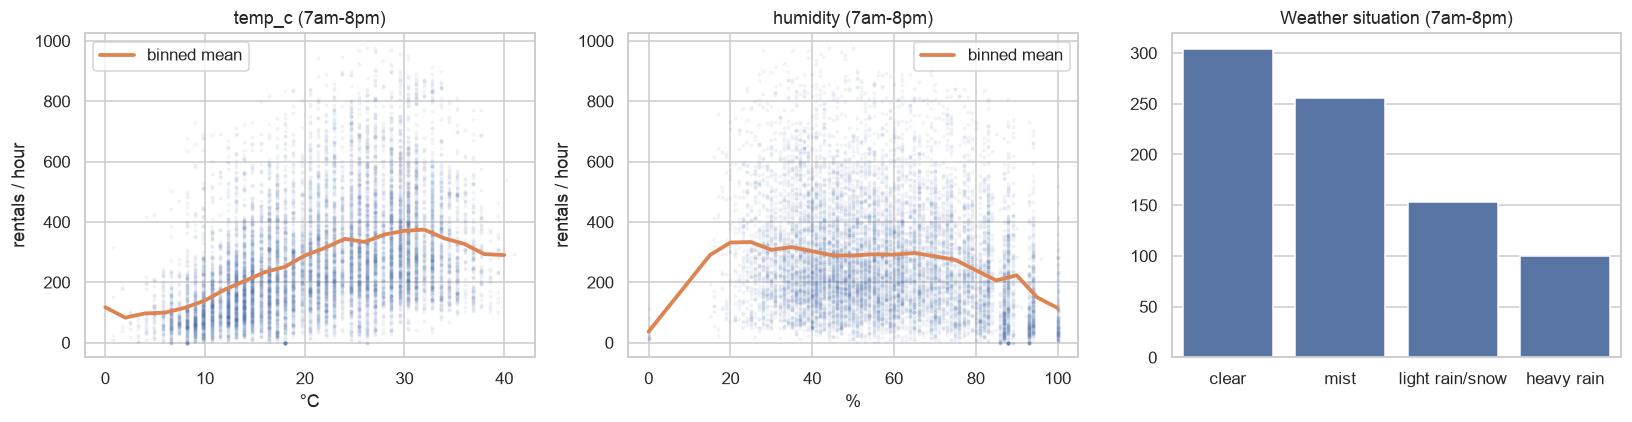

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
day = df[(df.index.hour >= 7) & (df.index.hour <= 20)]
for ax, col, step, unit in [(axes[0], 'temp_c', 2, '°C'), (axes[1], 'humidity', 5, '%')]:
    ax.scatter(day[col], day['cnt'], s=3, alpha=0.05)
    binned = day.groupby((day[col] / step).round() * step)['cnt'].mean()
    ax.plot(binned.index, binned.values, color='C1', lw=2.5, label='binned mean')
    ax.set(title=f'{col} (7am-8pm)', xlabel=unit, ylabel='rentals / hour')
    ax.legend()
labels = {1: 'clear', 2: 'mist', 3: 'light rain/snow', 4: 'heavy rain'}
sns.barplot(x=day['weather'].map(labels), y=day['cnt'], ax=axes[2], errorbar=None,
            order=list(labels.values()))
axes[2].set(title='Weather situation (7am-8pm)', xlabel='', ylabel='')
fig.tight_layout()

In [7]:
rel = day.groupby('weather')['cnt'].mean() / day.loc[day['weather'] == 1, 'cnt'].mean()
print('Demand relative to clear weather:', rel.round(2).to_dict())

Demand relative to clear weather: {1: 1.0, 2: 0.84, 3: 0.5, 4: 0.33}


* Demand rises with temperature up to roughly 30 °C, then flattens or falls, a non-linear effect (the Ridge model gets a squared temperature term).
* Light rain or snow cuts demand roughly in half compared with clear weather.

**Caveat for the model:** the dataset contains *observed* weather. At forecast time only a weather *forecast* is available, so backtest results with weather features are an upper bound. The backtest therefore also reports models **without weather**; the realistic accuracy lies between the two.

## 6. Decisions for modelling

| Finding | Decision |
|---|---|
| Missing hours are zero-demand or shutdowns | Fill with 0, keep a flag |
| +65% growth in one year | Predict demand / trailing 7-day level |
| Strong 24 h and 168 h cycles | Lags 24/48/168/336 h + same-hour 7-day mean |
| Commute vs. leisure regimes | Hour × working-day interaction |
| Count target, variance grows with level | Poisson objective (LightGBM), log target (Ridge) |
| Weather matters, but forecasts are uncertain | Report results with and without weather |
| Time-ordered data | Rolling-origin backtest, never random K-fold |